<a href="https://colab.research.google.com/github/vansestopier-codes/Ciencia-datos/blob/main/4.2%20Actividad%204%20EDA/Actividad4EDA_A01841600.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: VANESSA ESTOPIER TINAJERO
*   MATRÍCULA: A01841600

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd "/content/drive/MyDrive/Colab Notebooks/MNA - CyA de Datos/4.2 Actividad 4 | EDA"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Colab Notebooks/MNA - CyA de Datos/4.2 Actividad 4 | EDA


En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [2]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [3]:
loan_df = pd.read_csv('personal_loan.csv').set_index('ID')
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


**Respuesta:** Al dejar `ID` como índice, el dataframe tiene 5,037 registros y 13 columnas. De esas columnas, **8 son numéricas** (6 `int64`: Age, Experience, Income, ZIP Code, Family y Mortgage; y 2 `float64`: CCAvg y Education) y **5 son de texto** (`object`): Personal Loan, Securities Account, CD Account, Online y CreditCard.

Algo que llama la atención es que ZIP Code y Education salen como numéricas, pero en realidad son categorías. Eso se corrige en la pregunta 5.

# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [4]:
loan_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,5037.0,45.411356,11.646805,23.0,35.0,45.0,55.0,144.0
Experience,5037.0,20.122494,11.461278,-3.0,10.0,20.0,30.0,43.0
Income,5037.0,73.898352,46.130504,8.0,39.0,64.0,98.0,224.0
ZIP Code,5037.0,93152.865595,2119.637960,9307.0,91911.0,93437.0,94608.0,96651.0
Family,5037.0,2.394679,1.151145,-3.0,1.0,2.0,3.0,4.0
CCAvg,5037.0,1.942404,1.755954,0.0,0.7,1.5,2.6,10.0
Education,5037.0,1.880941,0.843337,1.0,1.0,2.0,3.0,7.3
Mortgage,5037.0,56.500695,101.657580,0.0,0.0,0.0,101.0,635.0


**Revisión de las estadísticas descriptivas:** al ver el mínimo y el máximo de cada columna encontré varios valores que no tienen sentido:

* `Age`: el máximo es 144 años, mientras que la media es de 45.
* `Experience`: el mínimo es -3, no puede haber años de experiencia negativos.
* `Family`: el mínimo es -3, el número de miembros de la familia no puede ser negativo.
* `Education`: el máximo es 7.3, pero la variable solo puede valer 1, 2 o 3.
* `ZIP Code`: el mínimo es 9307, que tiene 4 dígitos, mientras que el resto de los códigos son de 5 dígitos (entre 90000 y 96651).

`Income` (de 8 a 224 mil dólares al año), `CCAvg` (de 0 a 10 mil al mes) y `Mortgage` (de 0 a 635 mil) no tienen negativos y sus valores máximos, aunque altos, son posibles, así que no los toqué.

In [5]:
n_inicial = len(loan_df)
display(loan_df[loan_df['Age'] > 100])
loan_df = loan_df[loan_df['Age'] <= 100].copy()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


**Edades mayores a 100 años:** eliminé 3 registros (ID 10, 250 y 4800) con edades de 123, 144 y 130 años. No son posibles: la persona más longeva de la que se tiene registro vivió 122 años, y además ninguno de los tres es coherente con el resto de sus datos (por ejemplo, el cliente de 144 años solo tiene 6 de experiencia laboral). Parecen errores de captura y no hay forma de saber cuál era la edad real, por eso los eliminé.

In [6]:
exp_negativa = loan_df[loan_df['Experience'] < 0]
display(exp_negativa.head())
display(exp_negativa['Experience'].value_counts())
loan_df = loan_df[loan_df['Experience'] >= 0].copy()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
89,25,-1,113,94303,4,2.30,3.0,0,No,No,0,No,Yes
226,24,-1,39,94085,2,1.70,2.0,0,0,No,0,No,0
315,24,-2,51,90630,3,0.30,3.0,0,0,No,No,1,0
451,28,-2,48,94132,2,1.75,3.0,89,0,No,0,1,No
524,24,-1,75,93014,4,0.20,1.0,0,0,No,No,Yes,0


,count
Experience,
-1,34
-2,15
-3,4


**Experiencia negativa:** eliminé 53 registros con `Experience` de -1 (34 casos), -2 (15 casos) y -3 (4 casos). Los años de experiencia laboral no pueden ser negativos. Una opción sería cambiarles el signo, pero eso sería suponer un dato que no sabemos si es cierto, y como son pocos registros prefiero eliminarlos.

In [7]:
display(loan_df[loan_df['Family'] <= 0])
loan_df = loan_df[loan_df['Family'] > 0].copy()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
15,60,30,22,95054,-1,1.5,3.0,0,0,No,0,Yes,Yes
3000,40,14,164,94720,-3,4.3,2.0,0,1,No,No,No,No


**Tamaño de familia inválido:** eliminé 2 registros (ID 15 con `Family` = -1 e ID 3000 con `Family` = -3). El número de miembros de una familia no puede ser negativo, así que son errores.

In [8]:
display(loan_df[~loan_df['Education'].isin([1, 2, 3])])
loan_df = loan_df[loan_df['Education'].isin([1, 2, 3])].copy()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
347,25,0,43,94305,2,1.6,7.3,0,0,Yes,Yes,1,Yes


**Nivel educativo inválido:** eliminé 1 registro (ID 347) con `Education` = 7.3. Según la descripción de la variable solo existen los niveles 1, 2 y 3, y además es una categoría, por lo que un valor decimal como 7.3 no corresponde a ninguna.

In [9]:
display(loan_df[loan_df['ZIP Code'].astype(str).str.len() != 5])
loan_df = loan_df[loan_df['ZIP Code'].astype(str).str.len() == 5].copy()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
384,51,25,21,9307,4,0.6,3.0,0,No,0,0,1,Yes


**Código postal inválido:** eliminé 1 registro (ID 384) con `ZIP Code` = 9307. Los códigos postales de Estados Unidos tienen 5 dígitos y todos los demás de esta base están entre 90005 y 96651. Es probable que le falte un dígito, pero no hay forma de saber cuál, por eso lo eliminé.

In [10]:
loan_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,4977.0,45.582479,11.306960,24.0,36.0,46.0,55.0,67.0
Experience,4977.0,20.356038,11.299428,0.0,11.0,20.0,30.0,43.0
Income,4977.0,73.957002,46.207027,8.0,39.0,64.0,98.0,224.0
ZIP Code,4977.0,93167.200121,1762.076415,90005.0,91911.0,93437.0,94608.0,96651.0
Family,4977.0,2.390999,1.148632,1.0,1.0,2.0,3.0,4.0
CCAvg,4977.0,1.940719,1.756818,0.0,0.7,1.5,2.6,10.0
Education,4977.0,1.877034,0.839722,1.0,1.0,2.0,3.0,3.0
Mortgage,4977.0,56.675708,101.824409,0.0,0.0,0.0,101.0,635.0


Después de la limpieza, las estadísticas ya tienen sentido: `Age` va de 24 a 67 años, `Experience` de 0 a 43, `Family` de 1 a 4, `Education` de 1 a 3 y el código postal mínimo es 90005.

In [11]:
eliminados = n_inicial - len(loan_df)
pd.DataFrame({
    'Registros iniciales': [n_inicial],
    'Registros eliminados': [eliminados],
    'Porcentaje eliminado (%)': [round(eliminados / n_inicial * 100, 2)],
    'Registros restantes': [len(loan_df)]
})

,Registros iniciales,Registros eliminados,Porcentaje eliminado (%),Registros restantes
0,5037,60,1.19,4977


**Total de registros eliminados en esta pregunta:** 60 (3 por edad + 53 por experiencia negativa + 2 por familia + 1 por educación + 1 por código postal). Esto representa el **1.19 %** de los 5,037 registros iniciales, y quedaron 4,977 registros.

3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [12]:
text_cols = loan_df.select_dtypes(include=['object', 'string']).columns
loan_df[text_cols].describe()

,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4977,4977,4977,4977,4977
unique,4,4,4,4,4
top,0,No,No,Yes,0
freq,3475,2693,2462,1700,2628


In [13]:
for col in text_cols:
    print(loan_df[col].value_counts(), '\n')

Personal Loan
0      3475
No     1017
Yes     368
1       117
Name: count, dtype: int64 

Securities Account
No     2693
0      1765
Yes     390
1       129
Name: count, dtype: int64 

CD Account
No     2462
0      2212
1       163
Yes     140
Name: count, dtype: int64 

Online
Yes    1700
No     1628
1      1275
0       374
Name: count, dtype: int64 

CreditCard
0      2628
Yes     907
No      885
1       557
Name: count, dtype: int64 



Las 5 columnas de texto (`Personal Loan`, `Securities Account`, `CD Account`, `Online` y `CreditCard`) aparecen con **4 valores únicos** cada una cuando deberían tener solo 2. El problema es que el mismo dato está guardado en dos formatos: `Yes` / `No` y `1` / `0`. Por ejemplo, en `Personal Loan` hay 3,475 con "0", 1,017 con "No", 368 con "Yes" y 117 con "1". Para pandas son valores distintos aunque signifiquen lo mismo.

In [14]:
mapa_binario = {'Yes': 1, 'No': 0, '1': 1, '0': 0}
for col in text_cols:
    loan_df[col] = loan_df[col].map(mapa_binario)

In [15]:
display(loan_df[text_cols].apply(pd.Series.value_counts))
loan_df[text_cols].dtypes

,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,4492,4458,4674,2002,3513
1,485,519,303,2975,1464


,0
Personal Loan,int64
Securities Account,int64
CD Account,int64
Online,int64
CreditCard,int64


Unifiqué los formatos como indica la descripción de las variables: `Yes` y `1` pasan a ser **1** (sí), y `No` y `0` pasan a ser **0** (no). Después de convertir, cada columna tiene solo los valores 0 y 1, la suma de las frecuencias sigue siendo 4,977 (no se perdió ningún dato) y las columnas quedaron como `int64`.

4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [16]:
display(loan_df.duplicated().sum())
loan_df[loan_df.duplicated()].head()

np.int64(36)

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
5000,47,21,42,95841,4,0.1,1.0,0,0,0,0,1,1
5001,64,40,169,91320,2,2.1,1.0,122,0,0,0,1,0
5002,44,18,68,93943,4,2.9,1.0,0,0,1,0,0,0
5004,63,39,49,90275,1,0.8,1.0,103,0,0,0,1,0
5005,35,11,24,95521,4,0.4,2.0,0,0,0,0,0,0


Encontré **36 registros duplicados**, es decir, filas iguales en todas las columnas. Para detectarlos no se toma en cuenta el `ID` porque está como índice y es único. Todos los duplicados tienen un `ID` de 5000 en adelante, lo que sugiere que son copias de clientes anteriores que se agregaron al final de la base. Como un mismo cliente no debe contarse dos veces, los eliminé.

In [17]:
loan_df = loan_df.drop_duplicates().reset_index(drop=True)
display(loan_df.duplicated().sum())
display(loan_df.index)
loan_df.shape

np.int64(0)

RangeIndex(start=0, stop=4941, step=1)

(4941, 13)

Se eliminaron los 36 duplicados (se conserva la primera aparición de cada uno) y se reinició el índice con `reset_index(drop=True)`. Ahora el índice va de 0 a 4,940 sin saltos, y el dataframe tiene **4,941 registros** y 13 columnas. Con `drop=True` se descarta el `ID` anterior, que solo servía para identificar al cliente.

En total, desde el inicio se eliminaron 96 registros (60 de la limpieza más 36 duplicados).

5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [18]:
loan_df['ZIP Code'] = loan_df['ZIP Code'].astype(str).astype(object)
loan_df['Education'] = loan_df['Education'].astype(int).astype(pd.CategoricalDtype(categories=[1, 2, 3], ordered=True))

bin_cols = ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']
loan_df[bin_cols] = loan_df[bin_cols].astype('category')

display(loan_df['Education'].dtype)
loan_df.dtypes

CategoricalDtype(categories=[1, 2, 3], ordered=True, categories_dtype=int64)

,0
Age,int64
Experience,int64
Income,int64
ZIP Code,object
Family,int64
CCAvg,float64
Education,category
Mortgage,int64
Personal Loan,category
Securities Account,category


In [19]:
num_cols = loan_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = loan_df.select_dtypes(include=['object', 'category']).columns.tolist()

display(num_cols)
cat_cols

['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']

['ZIP Code',
 'Education',
 'Personal Loan',
 'Securities Account',
 'CD Account',
 'Online',
 'CreditCard']

Hice las conversiones que se pedían:

* `ZIP Code` pasó a `object`, porque es un código que identifica una zona y no tiene sentido sumarlo ni promediarlo.
* `Education` pasó a `category` ordenada (1 < 2 < 3), porque sus niveles sí tienen un orden.
* `Personal Loan`, `Securities Account`, `CD Account`, `Online` y `CreditCard` pasaron a `category`, porque solo toman los valores 0 y 1.

`Family` la dejé como numérica porque es un conteo de personas (los números sí tienen sentido matemático).

**`num_cols`** quedó con 6 variables (Age, Experience, Income, Family, CCAvg y Mortgage) y **`cat_cols`** con 7 (ZIP Code, Education y las 5 binarias).

# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [20]:
resumen = loan_df[num_cols].describe().T
resumen['skew'] = loan_df[num_cols].skew()
resumen['kurtosis'] = loan_df[num_cols].kurt()
resumen.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Age,4941.0,45.56,11.32,24.0,36.0,46.0,55.0,67.0,-0.02,-1.16
Experience,4941.0,20.34,11.31,0.0,11.0,20.0,30.0,43.0,-0.02,-1.13
Income,4941.0,73.83,46.11,8.0,39.0,64.0,98.0,224.0,0.84,-0.05
Family,4941.0,2.39,1.15,1.0,1.0,2.0,3.0,4.0,0.16,-1.40
CCAvg,4941.0,1.94,1.75,0.0,0.7,1.5,2.6,10.0,1.59,2.64
Mortgage,4941.0,56.66,101.88,0.0,0.0,0.0,101.0,635.0,2.10,4.76


**Clasificación de las variables.** Para interpretar usé estos criterios: en la asimetría, un valor entre -0.5 y 0.5 se considera simétrica, entre 0.5 y 1 asimetría moderada y mayor a 1 asimetría fuerte (el signo indica hacia dónde está la cola). La curtosis que calcula pandas es el exceso de curtosis, así que cerca de 0 es mesocúrtica (parecida a la normal), negativa es platicúrtica (más plana, colas ligeras) y positiva es leptocúrtica (más picuda, colas pesadas).

* **`Age`**: asimetría de -0.02, es **simétrica**. Curtosis de -1.16, es **platicúrtica**.
* **`Income`**: asimetría de 0.84, es **asimétrica positiva moderada** (cola hacia la derecha). Curtosis de -0.05, es **mesocúrtica**.
* **`Mortgage`**: asimetría de 2.10, es **asimétrica positiva fuerte**. Curtosis de 4.76, es **leptocúrtica**.

7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

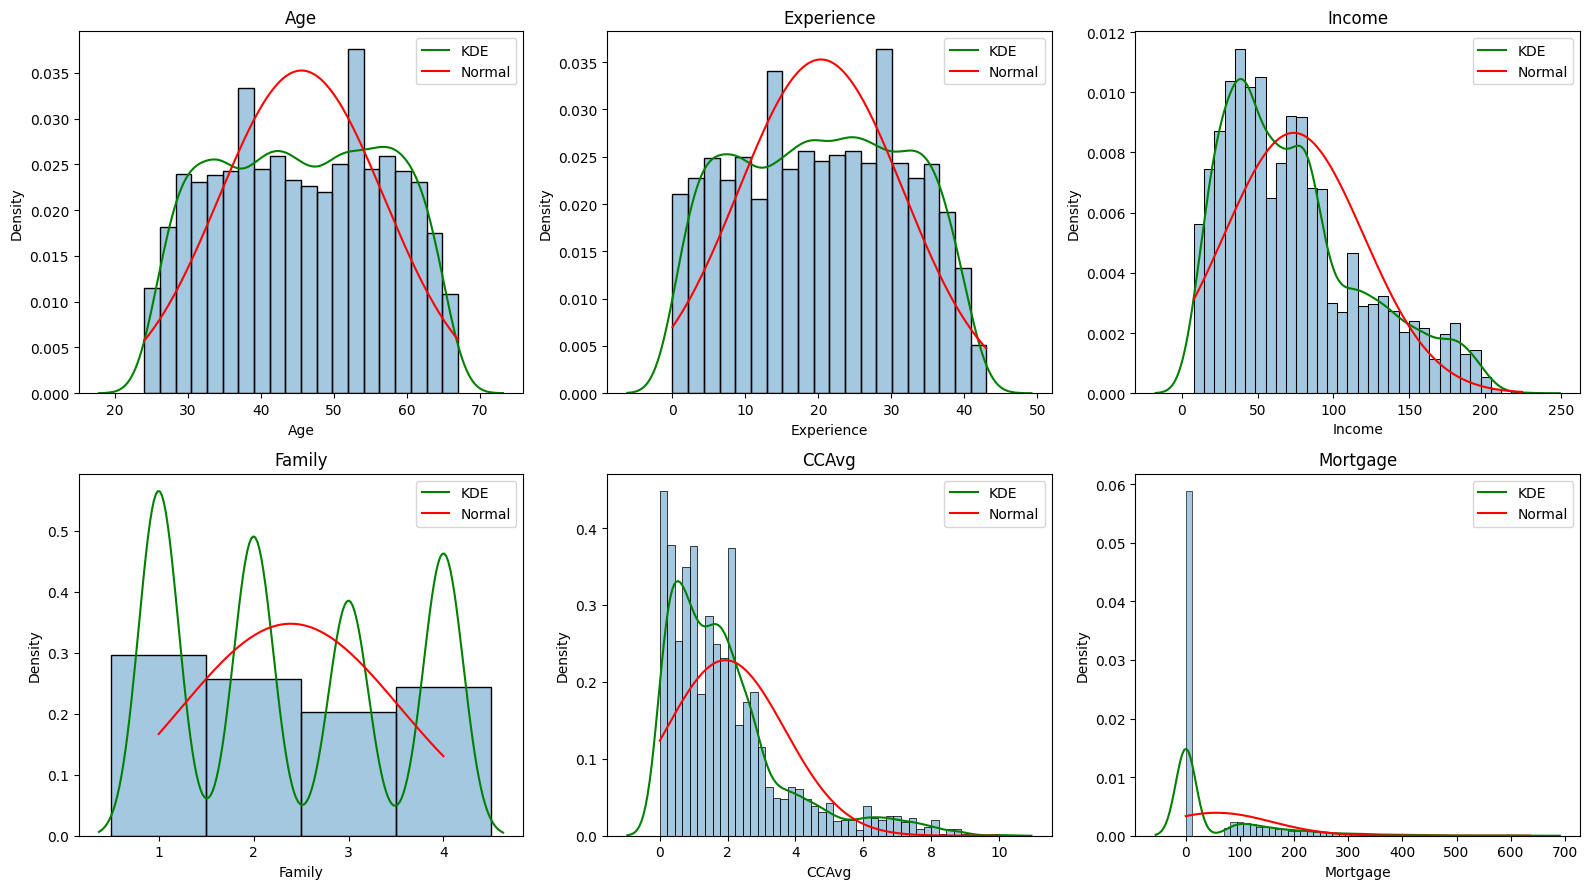

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(loan_df[col], stat='density', discrete=(col == 'Family'), alpha=0.4, ax=ax)
    sns.kdeplot(loan_df[col], color='green', label='KDE', ax=ax)
    x = np.linspace(loan_df[col].min(), loan_df[col].max(), 200)
    ax.plot(x, norm.pdf(x, loan_df[col].mean(), loan_df[col].std()), color='red', label='Normal')
    ax.set_title(col)
    ax.legend()

plt.tight_layout()
plt.show()

**Comparación de los histogramas con los valores calculados:**

* **`Age`**: coincide con lo esperado. El histograma es bastante plano entre los 25 y los 65 años, sin un pico en el centro como tendría una campana. Por eso la curva normal roja queda más alta y angosta que los datos (platicúrtica), y como los lados se ven parejos la asimetría es casi cero.
* **`Income`**: también coincide. Hay un pico entre los 30 y 60 mil y una cola larga hacia la derecha hasta los 224 mil, que es el sesgo positivo moderado (0.84). La curva normal queda corrida hacia la derecha del pico real. La curtosis cercana a 0 se refleja en que, aunque hay cola, no hay tantos valores extremos como para ser leptocúrtica.
* **`Mortgage`**: es el caso más marcado y también coincide. Hay una barra enorme en 0 (alrededor del 69 % de los clientes no tiene hipoteca) y el resto se reparte en una cola muy larga hasta 635 mil. No se parece nada a la normal, lo que cuadra con su asimetría fuerte (2.10) y su curtosis alta (4.76).

De las demás variables, `Experience` se ve parecida a `Age` (plana y simétrica), `CCAvg` tiene sesgo a la derecha (1.59) y `Family` solo toma 4 valores, por lo que su histograma son 4 barras y la curva normal no aplica bien.

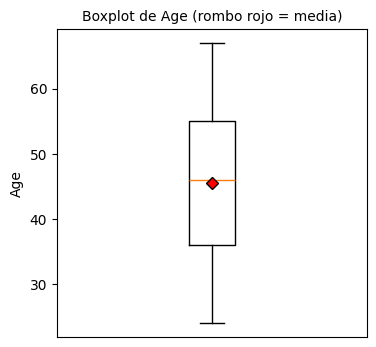

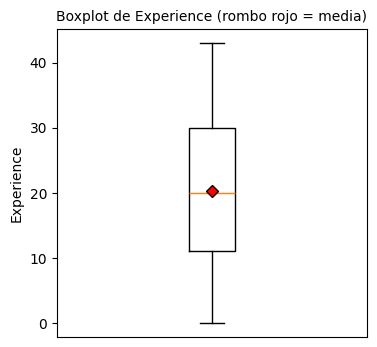

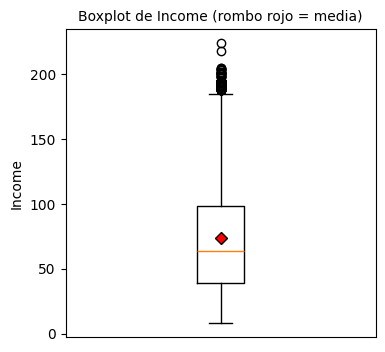

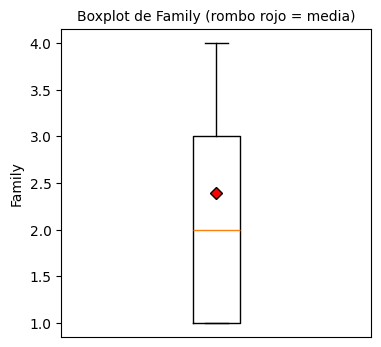

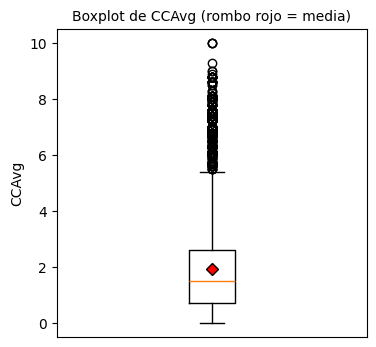

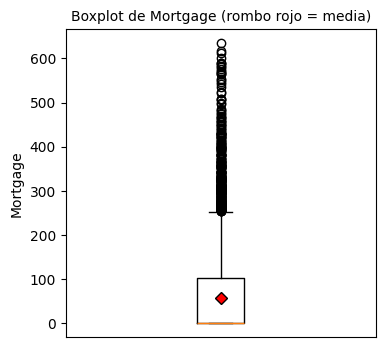

In [22]:
for col in num_cols:
    plt.figure(figsize=(4, 4))
    plt.boxplot(loan_df[col], showmeans=True,
                meanprops={'marker': 'D', 'markerfacecolor': 'red', 'markeredgecolor': 'black'})
    plt.title(f'Boxplot de {col} (rombo rojo = media)', fontsize=10)
    plt.ylabel(col)
    plt.xticks([])
    plt.show()

**Boxplots:** `Age`, `Experience` y `Family` tienen la caja bastante centrada y no muestran valores atípicos. `Income` y `CCAvg` tienen bastantes puntos por encima del bigote superior (clientes con ingresos o gastos mucho mayores al resto), y `Mortgage` es el más extremo: la caja está pegada al 0 (más de la mitad no tiene hipoteca) y hay muchos puntos atípicos hacia arriba.

In [23]:
pd.DataFrame({
    'Media': loan_df[num_cols].mean(),
    'Mediana': loan_df[num_cols].median(),
    'Media - Mediana': loan_df[num_cols].mean() - loan_df[num_cols].median()
}).round(2)

,Media,Mediana,Media - Mediana
Age,45.56,46.0,-0.44
Experience,20.34,20.0,0.34
Income,73.83,64.0,9.83
Family,2.39,2.0,0.39
CCAvg,1.94,1.5,0.44
Mortgage,56.66,0.0,56.66


**Media contra mediana:**

* En `Age` (45.56 vs 46) y `Experience` (20.34 vs 20) la media y la mediana casi coinciden, lo que indica una distribución simétrica, igual que sus valores de asimetría cercanos a 0.
* En `Income` la media (73.83) es mayor que la mediana (64), y en `CCAvg` también (1.94 vs 1.5). Cuando la media es mayor que la mediana, los valores altos la están jalando hacia arriba, lo que indica **sesgo positivo** (cola a la derecha).
* En `Mortgage` la diferencia es la mayor: la mediana es 0 y la media es 56.66. Es un sesgo positivo muy fuerte, por los pocos clientes con hipotecas altas.
* `Family` tiene una diferencia pequeña (2.39 vs 2), con un sesgo positivo leve.

Ninguna variable tiene la media claramente por debajo de la mediana, así que no hay sesgo negativo importante. Esto coincide con los valores de asimetría que calculé antes.

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

In [24]:
loan_df[cat_cols].describe()

,ZIP Code,Education,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4941,4941,4941,4941,4941,4941,4941
unique,467,3,2,2,2,2,2
top,94720,1,0,0,0,1,0
freq,163,2079,4462,4426,4640,2951,3489


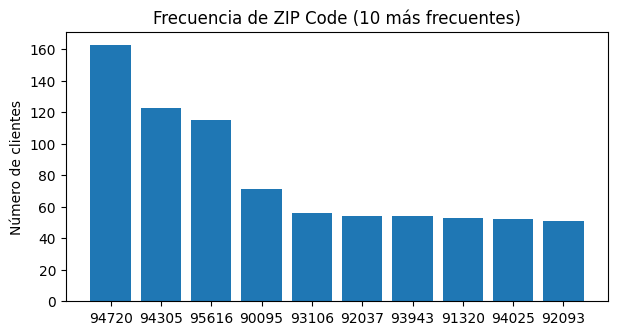

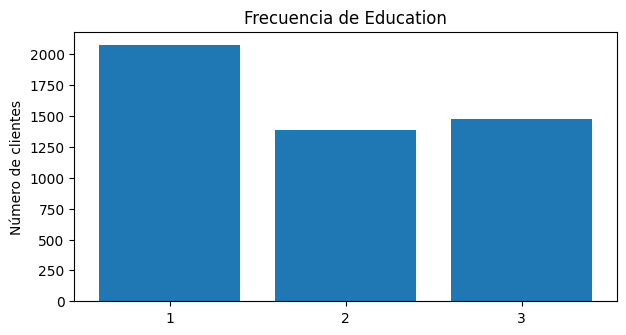

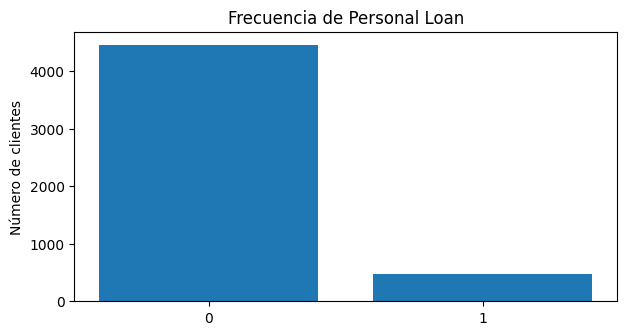

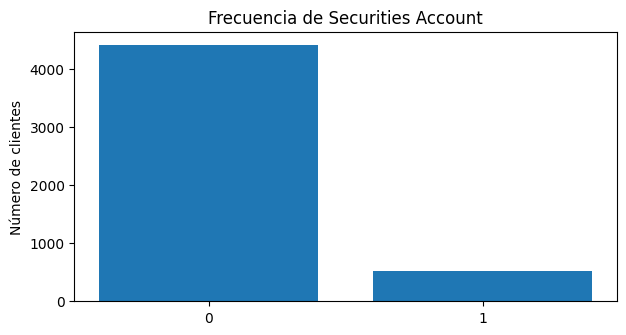

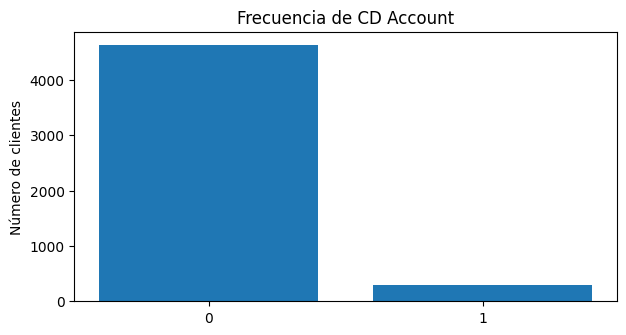

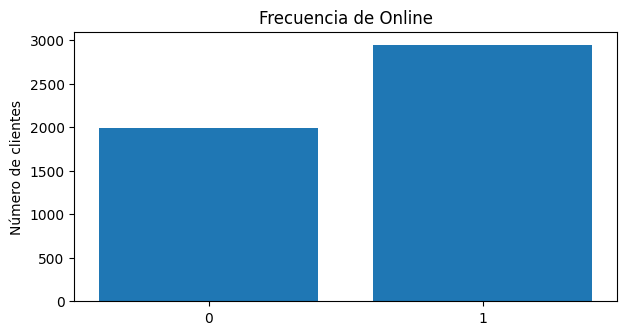

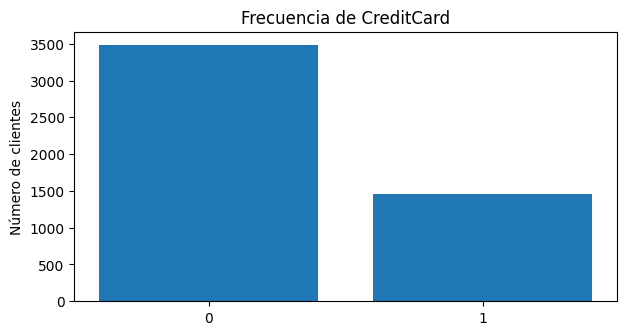

In [25]:
for col in cat_cols:
    conteo = loan_df[col].value_counts()
    conteo = conteo.head(10) if col == 'ZIP Code' else conteo.sort_index()
    plt.figure(figsize=(7, 3.5))
    plt.bar(conteo.index.astype(str), conteo.values)
    plt.title(f'Frecuencia de {col}' + (' (10 más frecuentes)' if col == 'ZIP Code' else ''))
    plt.ylabel('Número de clientes')
    plt.show()

**Variables categóricas:**

* `ZIP Code` tiene **alta cardinalidad**: 467 códigos distintos, y el más frecuente (94720) solo aparece 163 veces. Por eso en su gráfico solo se muestran los 10 más frecuentes. Esos 10 juntos representan apenas el 16 % de los clientes, así que la mayoría de los códigos tiene muy pocos clientes.
* `Education` tiene 3 niveles y el más común es el 1 (2,079 clientes, 42 %), mientras que los niveles 2 y 3 están parecidos (28 % y 30 %).
* `Personal Loan` está **desbalanceada**: 4,462 clientes no aceptaron el préstamo (90.3 %) y solo 479 sí lo aceptaron (9.7 %). Es algo importante a tener en cuenta cuando se haga el modelo.
* `Securities Account` y `CD Account` son poco comunes: 10.4 % y 6.1 % de los clientes las tienen, respectivamente.
* `Online`: la mayoría de los clientes usa la banca en línea (59.7 %).
* `CreditCard`: el 29.4 % tiene tarjeta de crédito del banco.

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

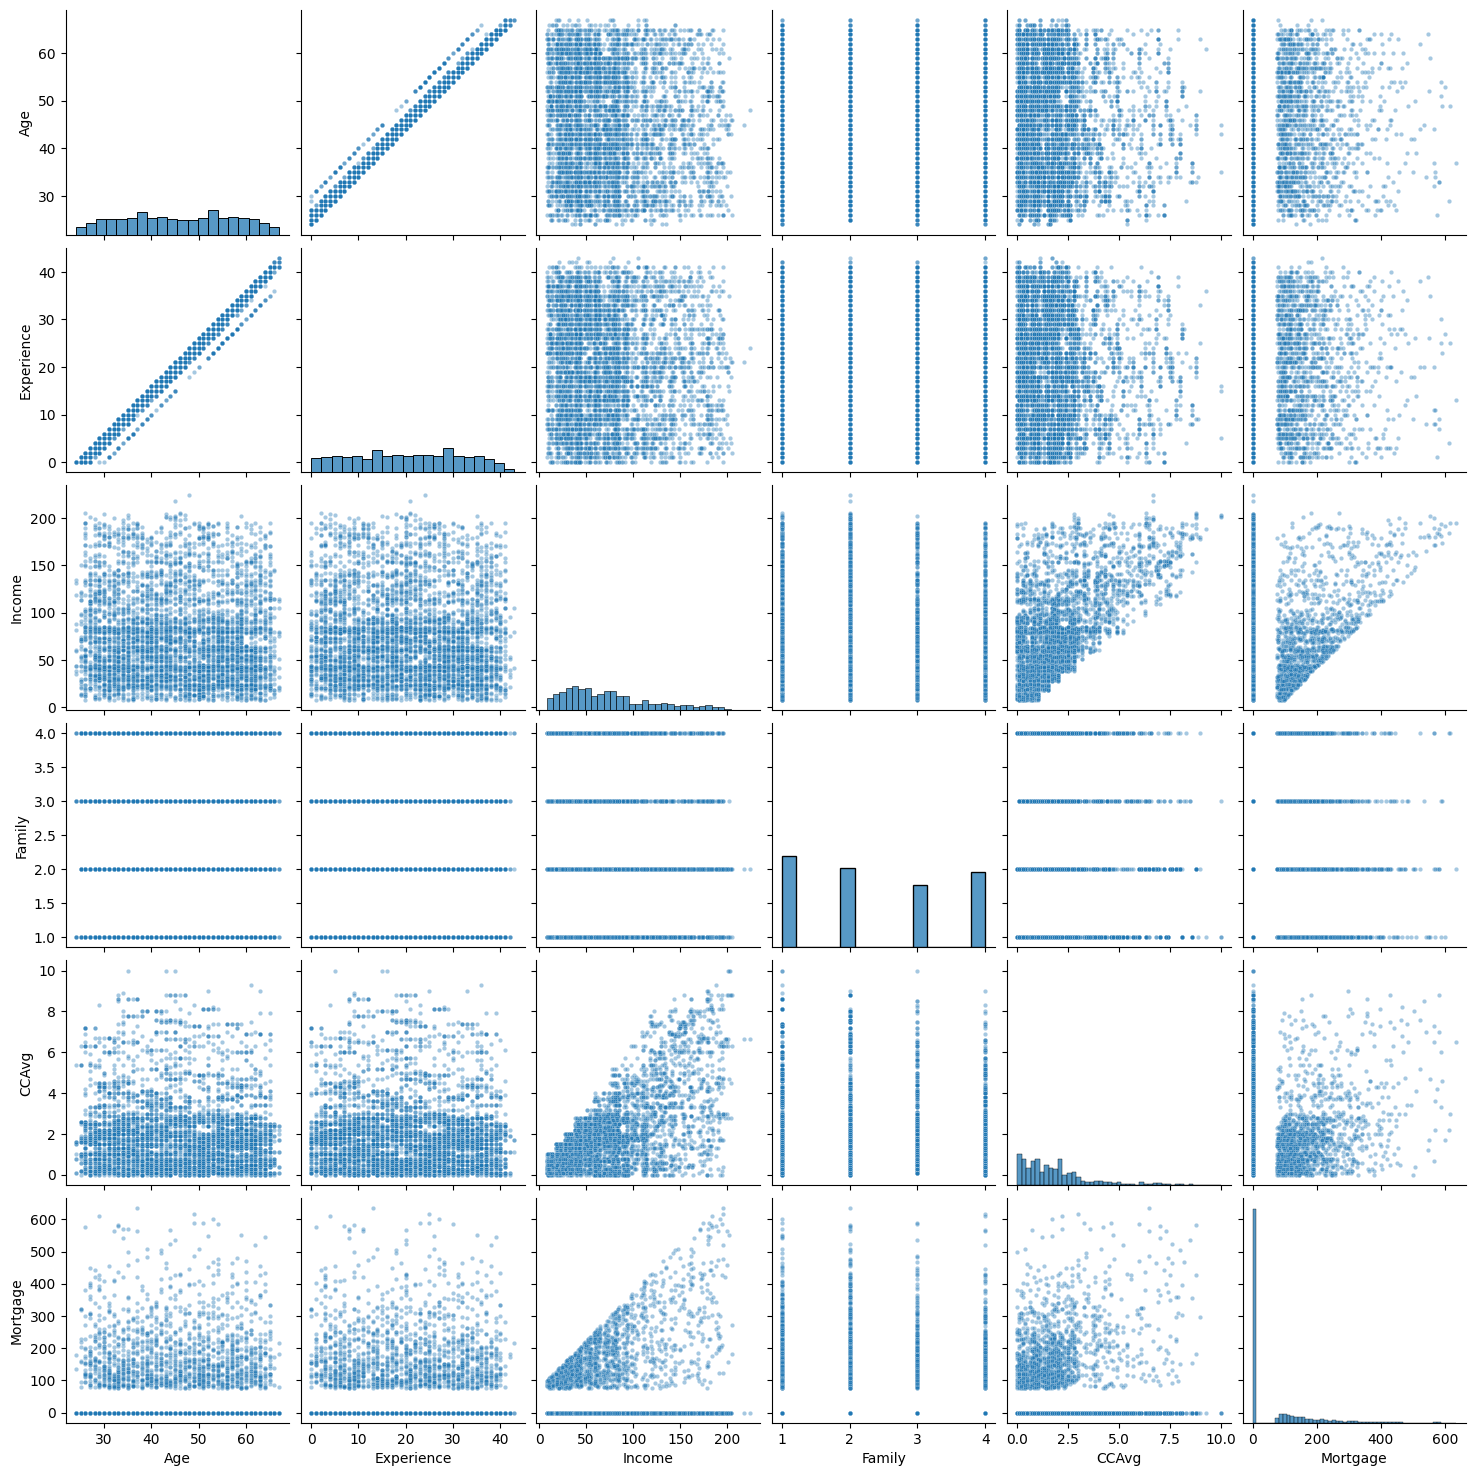

In [26]:
sns.pairplot(loan_df[num_cols], plot_kws={'alpha': 0.4, 's': 10})
plt.show()

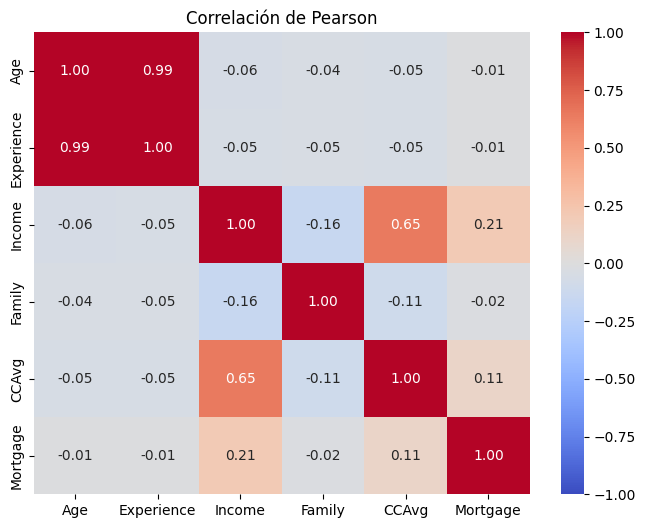

In [27]:
plt.figure(figsize=(8, 6))
sns.heatmap(loan_df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlación de Pearson')
plt.show()

**Par seleccionado: `Age` y `Experience`.** En la matriz de dispersión los puntos forman una línea diagonal casi perfecta: a mayor edad, mayor experiencia laboral. Tiene sentido porque la experiencia se acumula con los años, y la diferencia entre ambas es casi constante (más o menos 25 años, que sería la edad en que empezaron a trabajar).

El mapa de calor muestra una correlación de Pearson de **0.99** entre ellas, así que el valor numérico **sí se corresponde con lo esperado** al ver la gráfica: relación lineal positiva casi perfecta. Esto también significa que las dos variables casi dicen lo mismo (están muy correlacionadas entre sí).

Otro par que se nota es `Income` y `CCAvg`, con una correlación positiva moderada de 0.65: quienes tienen más ingreso tienden a gastar más con tarjeta. El resto de los pares tienen correlaciones cercanas a 0 (entre -0.16 y 0.21), es decir, relaciones lineales muy débiles.

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


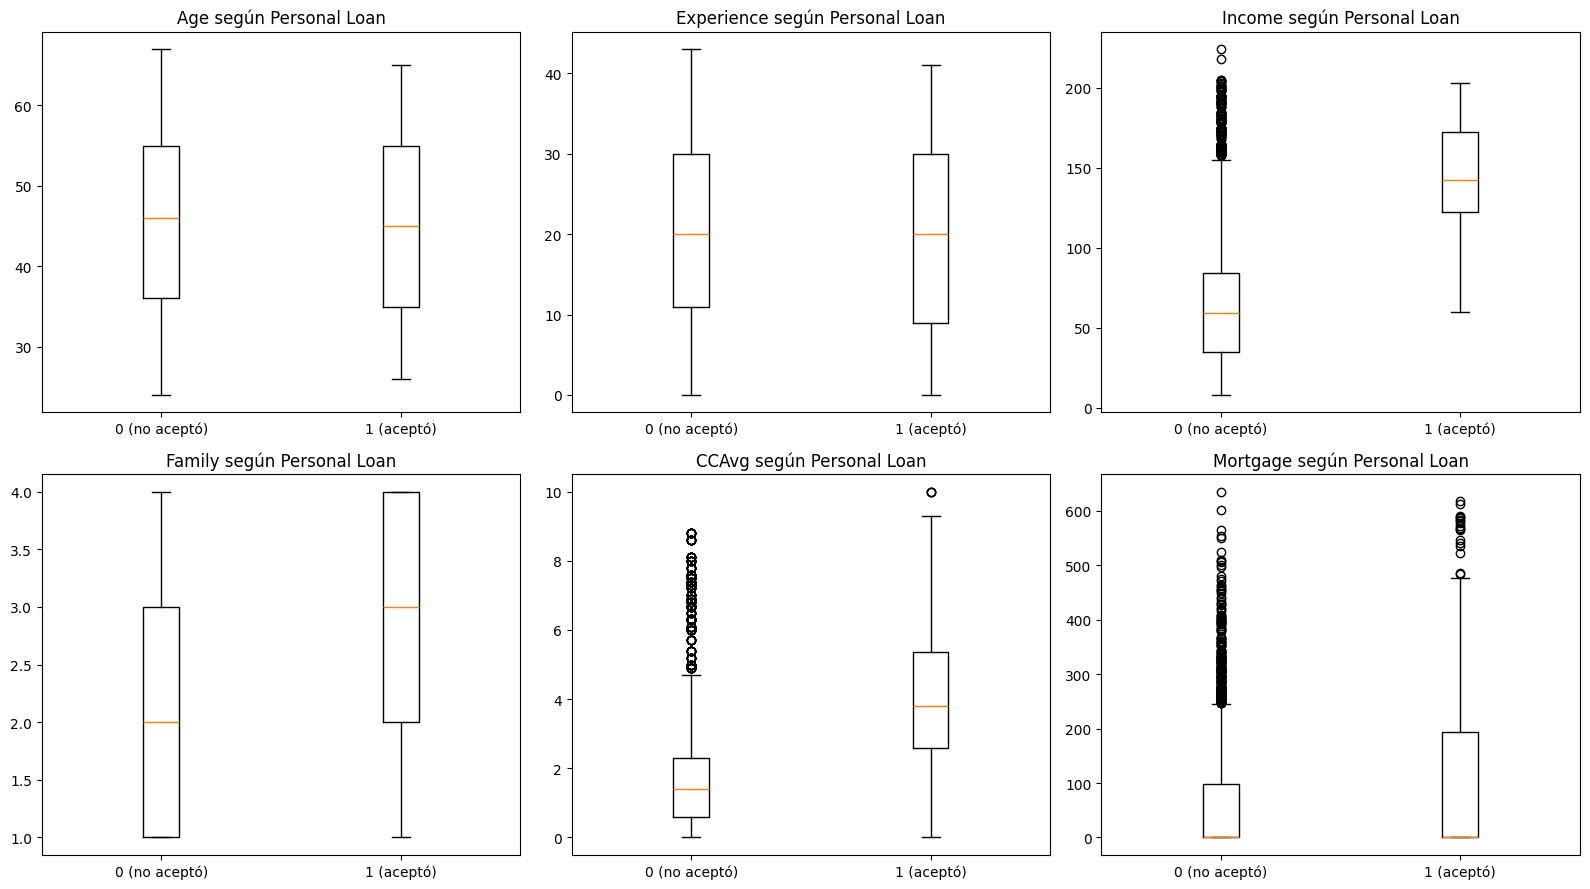

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flatten(), num_cols):
    sin_prestamo = loan_df.loc[loan_df['Personal Loan'] == 0, col]
    con_prestamo = loan_df.loc[loan_df['Personal Loan'] == 1, col]
    ax.boxplot([sin_prestamo, con_prestamo])
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['0 (no aceptó)', '1 (aceptó)'])
    ax.set_title(f'{col} según Personal Loan')

plt.tight_layout()
plt.show()

**Hallazgos en las variables numéricas:** las variables que más diferencian a quienes aceptaron el préstamo son `Income` y `CCAvg`. Los clientes que aceptaron tienen un ingreso mediano de 142 mil, contra 59 mil de quienes no aceptaron, y sus cajas no se traslapan. Algo parecido pasa con `CCAvg` (sus cajas tampoco se traslapan): la mediana es 3.8 mil con préstamo y 1.4 mil sin préstamo. `Family` también muestra una diferencia (mediana de 3 contra 2). En cambio, `Age` y `Experience` se ven casi iguales en los dos grupos, por lo que no parecen ayudar a distinguir quién acepta. En `Mortgage` la mediana es 0 en ambos grupos, pero entre quienes aceptaron la caja llega más arriba.

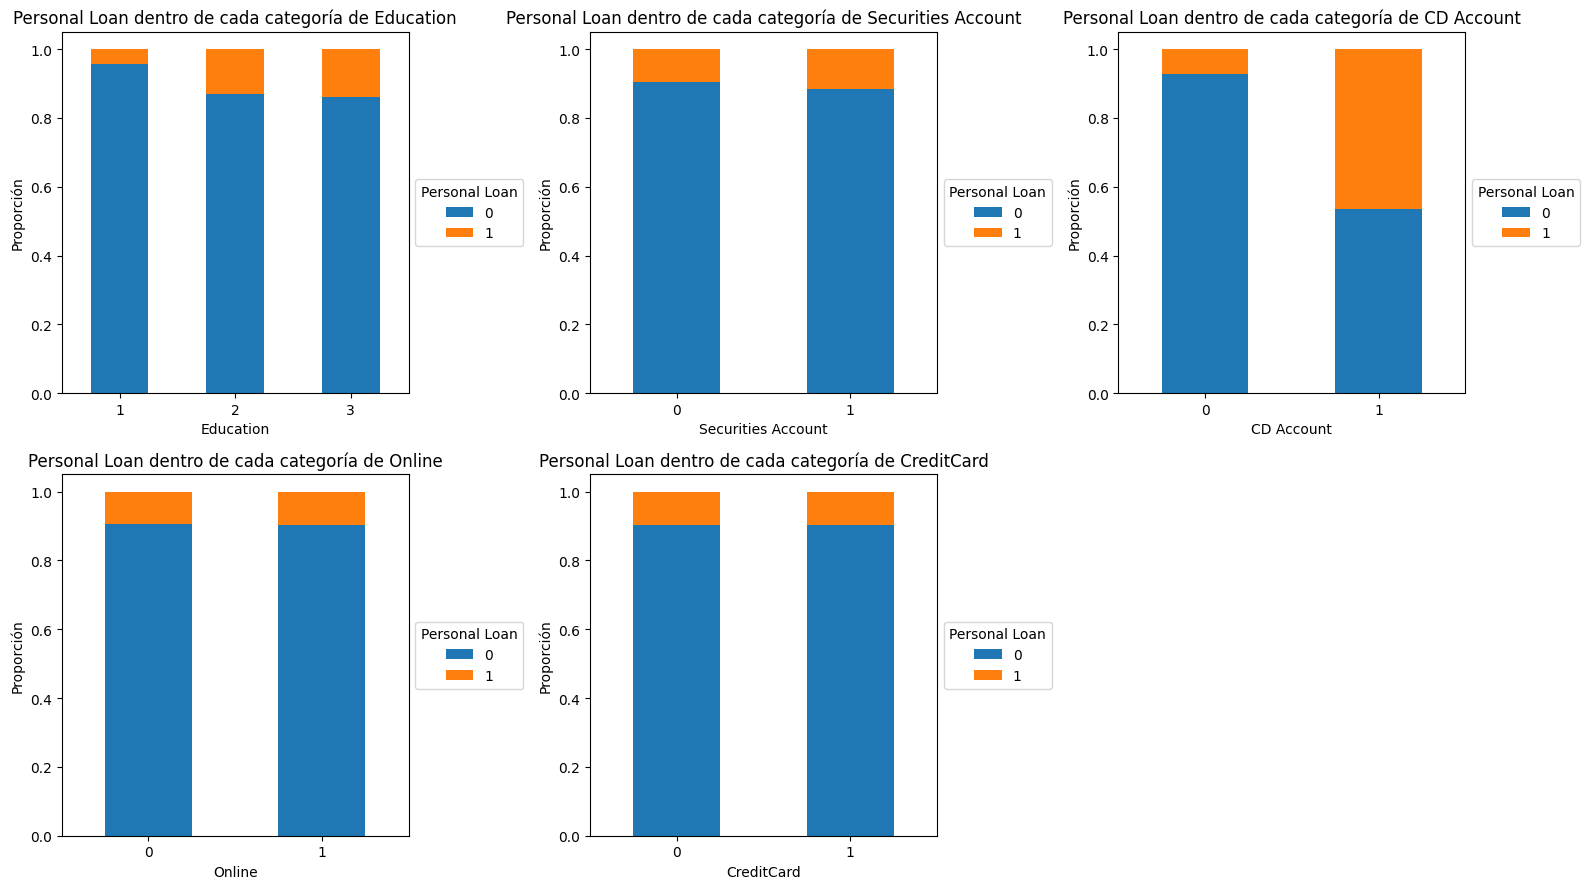

In [29]:
cat_sin_zip = [c for c in cat_cols if c not in ['ZIP Code', 'Personal Loan']]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flatten(), cat_sin_zip):
    pd.crosstab(loan_df[col], loan_df['Personal Loan'], normalize='index').plot(kind='bar', stacked=True, ax=ax)
    ax.set_title(f'Personal Loan dentro de cada categoría de {col}')
    ax.set_ylabel('Proporción')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(title='Personal Loan', loc='center left', bbox_to_anchor=(1, 0.5))

axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()

**Hallazgos en las variables categóricas:** el más claro es `CD Account`: entre los clientes que tienen cuenta de certificado de depósito, el 46.5 % aceptó el préstamo, contra solo el 7.3 % de los que no la tienen. También hay diferencia con `Education`: aceptó el 4.5 % del nivel 1, mientras que en los niveles 2 y 3 fue el 13.1 % y 13.9 %. En cambio, `Securities Account`, `Online` y `CreditCard` casi no cambian entre sus categorías (todas rondan el 10 %), así que por sí solas no parecen relacionadas con aceptar el préstamo.

Hay que tener en cuenta que estas gráficas muestran proporciones dentro de cada categoría, y no cuántos clientes hay: por ejemplo, solo el 6 % de los clientes tiene `CD Account`.

[texto del vínculo](https://)---

**Declaración de uso de IA**


*  **Declaración de uso de IA**

- Anthropic. (2026). *Claude (Claude Sonnet 5.5)* [Modelo de lenguaje grande], utilizado para validar sintaxis de Python, aclarar dudas sobre comandos y revisar posibles errores en el código. El desarrollo de la actividad, la elaboración del código y el análisis de los resultados fueron realizados de manera independiente y son de mi autoría.

  https://claude.ai/

---